In [15]:
import pandas as pd
import csv
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pickle

In [6]:
SPIKE_PATH = '/home/gwyneth-local/celegans_connectome_analysis/data/data_derivatives/spike_correlations.csv'

In [7]:
df = pandas.read_csv(SPIKE_PATH)

In [8]:
df.head()

,n1,n2,n3,direction,and_corr,or_corr,and_notb_corr,and_nota_corr,not_not_corr,a_corr,b_corr
0,ASEL,ADEL,ASER,->n3,-0.019832,0.021821,0.040434,-0.002705,-0.021821,0.030383,-0.010343
1,ASEL,ADEL,ASER,->n2,-0.014730,0.035375,0.061668,-0.005269,-0.035375,0.052236,-0.010343
2,ASEL,ADEL,ASER,->n1,-0.005403,0.063332,0.056423,0.033154,-0.063332,0.052236,0.030383
3,ASEL,ADEL,ASER,->n3,-0.003716,0.015862,0.047518,-0.022403,-0.015862,0.043831,-0.022596
4,ASEL,ADEL,ASER,->n2,-0.009359,-0.000142,0.024051,-0.020386,0.000142,0.019237,-0.022596


In [12]:
df['corr_diff'] = abs(df['and_corr']) - abs(df['or_corr'])
df.sort_values(by='corr_diff', ascending=False, inplace=True)

In [13]:
df.head(30)

,n1,n2,n3,direction,and_corr,or_corr,and_notb_corr,and_nota_corr,not_not_corr,a_corr,b_corr,corr_diff
961671,ASGL,AWAL,AVAL,->n3,0.502572,0.215166,-0.000202,0.036471,-0.215166,0.226030,0.305942,0.287406
1658037,AWAL,AVEL,AVAL,->n3,0.459524,0.182531,0.000331,0.115809,-0.182531,0.138453,0.302668,0.276993
3700050,AVER,AUAL,AIBR,->n3,0.270048,-0.002645,0.004575,-0.039857,0.002645,0.058290,-0.005845,0.267403
1147222,ASGL,AIBL,AIBR,->n2,0.526703,0.259640,0.028418,0.153396,-0.259640,0.215387,0.479405,0.267063
1147221,ASGL,AIBL,AIBR,->n3,0.488369,0.230918,0.002112,0.168755,-0.230918,0.183692,0.479405,0.257451
204295,ASEL,AIBL,AIBR,->n2,0.507914,0.253239,0.012417,0.213203,-0.253239,0.178179,0.479405,0.254675
3255390,OLLL,SMDVR,SIBDL,->n3,0.281121,0.032778,-0.010131,-0.025078,-0.032778,0.078458,0.047076,0.248343
3909838,AVER,AVAL,AVL,->n2,0.525758,0.277916,0.005790,0.090777,-0.277916,0.271174,0.387415,0.247842
204294,ASEL,AIBL,AIBR,->n3,0.452780,0.214643,-0.025714,0.232709,-0.214643,0.135559,0.479405,0.238137
3909837,AVER,AVAL,AVL,->n3,0.516846,0.285421,0.028854,0.092018,-0.285421,0.276846,0.387415,0.231425


In [16]:
DATA_PATH = 'data/data_derivatives/obs_func.gpickle'
with open(DATA_PATH, 'rb') as f:
    obs_func = pickle.load(f)

In [32]:
# neu1, neu2, neu3 = 'ASGL', 'AWAL', 'AVAL'
neu1, neu2, neu3 = 'AVER', 'AUAL', 'AIBR'

In [33]:
def analyze_neuron_paths(obs_func, n1, n2, n3):
    """
    Analyze neuron types and paths between three neurons in the connectome.
    """
    # Get neuron objects
    neuron1, neuron2, neuron3 = obs_func.nodes[n1], obs_func.nodes[n2], obs_func.nodes[n3]
    
    # Print neuron types
    print(f"{n1} type:", neuron1['neuron type'])
    print(f"{n2} type:", neuron2['neuron type'])
    print(f"{n3} type:", neuron3['neuron type'])

    # Get path lengths
    n1_to_n3_len = nx.shortest_path_length(obs_func, n1, n3)
    n2_to_n3_len = nx.shortest_path_length(obs_func, n2, n3)

    print(f"\nPath length {n1}->{n3}: {n1_to_n3_len}")
    print(f"Path length {n2}->{n3}: {n2_to_n3_len}")

    # Get full paths
    n1_to_n3_path = nx.shortest_path(obs_func, n1, n3)
    n2_to_n3_path = nx.shortest_path(obs_func, n2, n3)

    print(f"\nPath {n1}->{n3}:", ' -> '.join(n1_to_n3_path))
    print(f"Path {n2}->{n3}:", ' -> '.join(n2_to_n3_path))

# Call function with default values
analyze_neuron_paths(obs_func,
                     n1=neu1,
                     n2=neu2,
                     n3=neu3)




AVER type: Inter.
AUAL type: Sens.
AIBR type: Inter.

Path length AVER->AIBR: 2
Path length AUAL->AIBR: 2

Path AVER->AIBR: AVER -> RMDVL -> AIBR
Path AUAL->AIBR: AUAL -> RMDVL -> AIBR


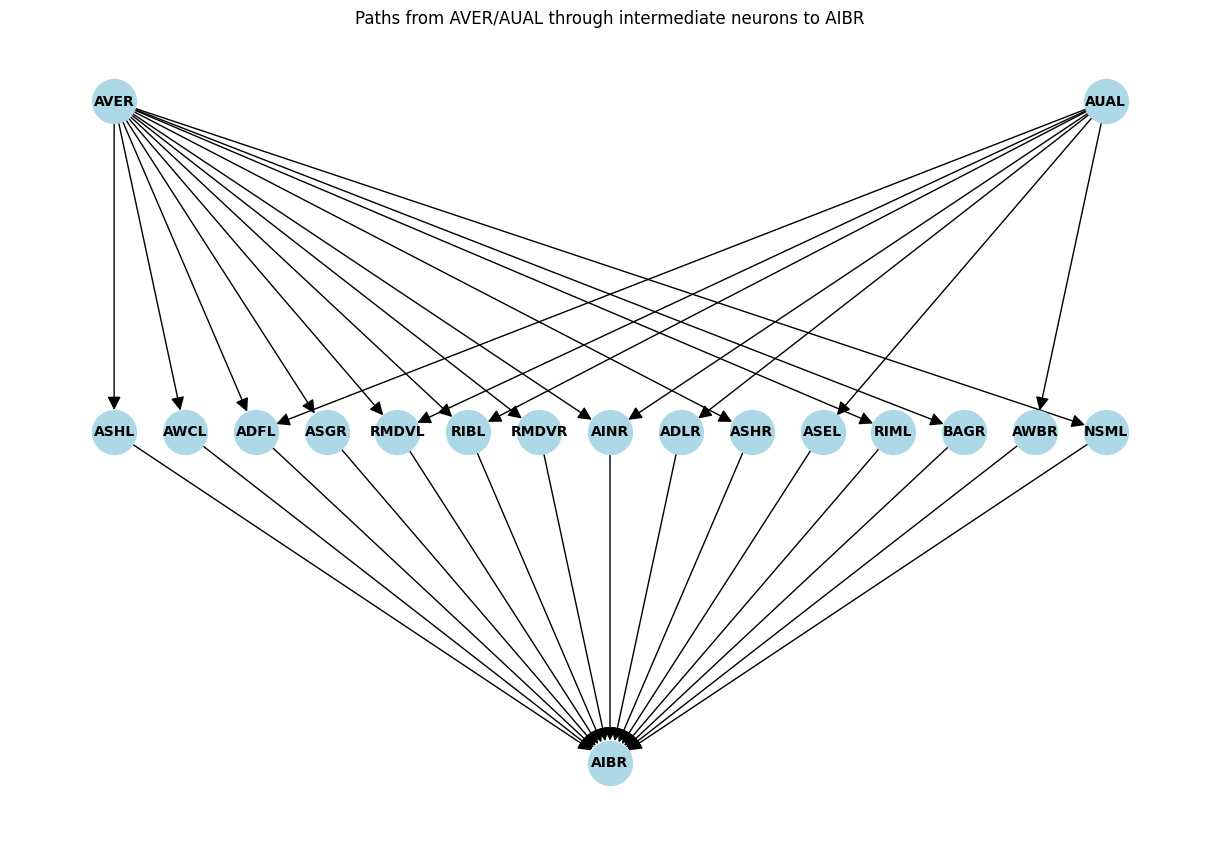

In [34]:
def plot_three_layer_paths(obs_func, n1, n2, n3):
    """
    Plot three layer graph showing paths from two input neurons to an output neuron.
    
    Args:
        obs_func: NetworkX DiGraph containing the connectome
        n1: First input neuron name
        n2: Second input neuron name 
        n3: Output neuron name
    """
    # Get all neurons that are one step from inputs and one step from output
    n1_out = set(obs_func.successors(n1))
    n2_out = set(obs_func.successors(n2))
    n3_in = set(obs_func.predecessors(n3))

    # Middle layer neurons are those that connect to both input and output
    middle_layer = list((n1_out | n2_out) & n3_in)

    # Create a new directed graph for visualization
    G = nx.DiGraph()

    # Add nodes with positions
    # Top layer (input neurons)
    G.add_node(n1, pos=(-0.5, 2))
    G.add_node(n2, pos=(0.5, 2))

    # Middle layer (neurons that connect input to output)
    spacing = 1.0 / max(1, len(middle_layer)-1)
    for i, neuron in enumerate(middle_layer):
        G.add_node(neuron, pos=(-0.5 + i*spacing, 1))

    # Bottom layer (output neuron)
    G.add_node(n3, pos=(0, 0))

    # Add edges
    for n in middle_layer:
        if n in n1_out:
            G.add_edge(n1, n)
        if n in n2_out:
            G.add_edge(n2, n)
        if obs_func.has_edge(n, n3):
            G.add_edge(n, n3)

    # Draw the graph
    plt.figure(figsize=(12, 8))
    pos = nx.get_node_attributes(G, 'pos')
    nx.draw(G, pos, with_labels=True, node_color='lightblue', 
            node_size=1000, arrowsize=20, font_size=10,
            font_weight='bold')
    plt.title(f'Paths from {n1}/{n2} through intermediate neurons to {n3}')
    plt.show()
    
plot_three_layer_paths(obs_func, neu1, neu2, neu3)

In [35]:
# get path lengths

def path_lengths(obs_func, n1, n2, n3):
    """
    Get path lengths between three neurons in the connectome.
    """
    # Get path lengths
    n1_to_n3_len = nx.shortest_path_length(obs_func, n1, n3)
    n2_to_n3_len = nx.shortest_path_length(obs_func, n2, n3)
    
    return n1_to_n3_len, n2_to_n3_len

# Print path lengths for top 30 entries
for _, row in df.head(30).iterrows():
    n1, n2, n3 = row['n1'], row['n2'], row['n3']
    try:
        n1_len, n2_len = path_lengths(obs_func, n1, n2, n3)
        print(f"{n1}->{n3}: {n1_len} steps, {n2}->{n3}: {n2_len} steps")
    except nx.NetworkXNoPath:
        print(f"No path exists between some of: {n1}, {n2}, {n3}")


ASGL->AVAL: 2 steps, AWAL->AVAL: 2 steps
AWAL->AVAL: 2 steps, AVEL->AVAL: 1 steps
AVER->AIBR: 2 steps, AUAL->AIBR: 2 steps
ASGL->AIBR: 2 steps, AIBL->AIBR: 1 steps
ASGL->AIBR: 2 steps, AIBL->AIBR: 1 steps
ASEL->AIBR: 1 steps, AIBL->AIBR: 1 steps
OLLL->SIBDL: 3 steps, SMDVR->SIBDL: 3 steps
AVER->AVL: 3 steps, AVAL->AVL: 3 steps
ASEL->AIBR: 1 steps, AIBL->AIBR: 1 steps
AVER->AVL: 3 steps, AVAL->AVL: 3 steps
No path exists between some of: AVER, AVL, M4
AVER->RMDR: 1 steps, OLLR->RMDR: 1 steps
AWAL->AVL: 3 steps, AVER->AVL: 3 steps
AVER->AVAL: 2 steps, SAAVL->AVAL: 1 steps
AWAL->AVAL: 2 steps, AVEL->AVAL: 1 steps
OLLL->AIBR: 2 steps, AIBL->AIBR: 1 steps
ASGL->AVAL: 2 steps, AVEL->AVAL: 1 steps
ASGL->AVAL: 2 steps, AWAL->AVAL: 2 steps
ASGL->CEPDR: 2 steps, AIBR->CEPDR: 2 steps
ASGL->RIR: 2 steps, SIBVR->RIR: 3 steps
No path exists between some of: AVER, AVL, M4
No path exists between some of: ASER, AUAR, AIY?
ASER->RMEV: 2 steps, AIBR->RMEV: 2 steps
AWAL->OLQVL: 2 steps, AIBL->OLQVL: 2 ste